In [1]:
%pip install numpy==2.5.4 matplotlib==3.11.2 scipy==1.18.1 librosa==1.0.0 sounddevice==0.5.6

  Using cached numpy-2.5.4-cp314-cp314-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached librosa-1.0.0-py3-none-any.whl.metadata (6.7 kB)
  Using cached sounddevice-0.5.6-py3-none-macosx_10_6_x86_64.macosx_10_6_universal2.whl.metadata (1.4 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp314-cp314-macosx_10_15_universal2.whl.metadata (137 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached numba-0.68.0-cp314-cp314-macosx_12_0_arm64.whl.metadata (2.8 kB)
  Using cached scikit_learn-1.9.1-cp314-

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import sounddevice as sd
import librosa

from IPython.display import display, Markdown, Audio

# Audio configuration
SR = 16000
DURATION = 1.0

# Feature extraction configuration
FRAME_MS = 25
HOP_MS = 10
N_FFT = 512
N_MELS = 80

FRAME = int(SR * FRAME_MS / 1000)  # 400 samples
HOP = int(SR * HOP_MS / 1000)      # 160 samples

print(f"Sample rate: {SR} Hz")
print(f"Recording duration: {DURATION} second")
print(f"Frame length: {FRAME} samples")
print(f"Hop length: {HOP} samples")
print(f"FFT size: {N_FFT}")
print(f"Mel bands: {N_MELS}")

Sample rate: 16000 Hz
Recording duration: 1.0 second
Frame length: 400 samples
Hop length: 160 samples
FFT size: 512
Mel bands: 80


In [14]:
display(Markdown("## Step 1: Record audio"))

print("Speak now...")

audio = sd.rec(
    int(SR * DURATION),
    samplerate=SR,
    channels=1,
    dtype="float32"
)

sd.wait()
audio = audio.flatten()

t_audio = np.arange(len(audio)) / SR

print("Recording complete.")
print("Number of samples:", len(audio))
print("Duration:", len(audio) / SR, "seconds")

display(Audio(audio, rate=SR))

## Step 1: Record audio

Speak now...
Recording complete.
Number of samples: 16000
Duration: 1.0 seconds



## Step 2: Original waveform

The horizontal axis is time. The vertical axis is the digital
amplitude of the recorded audio.


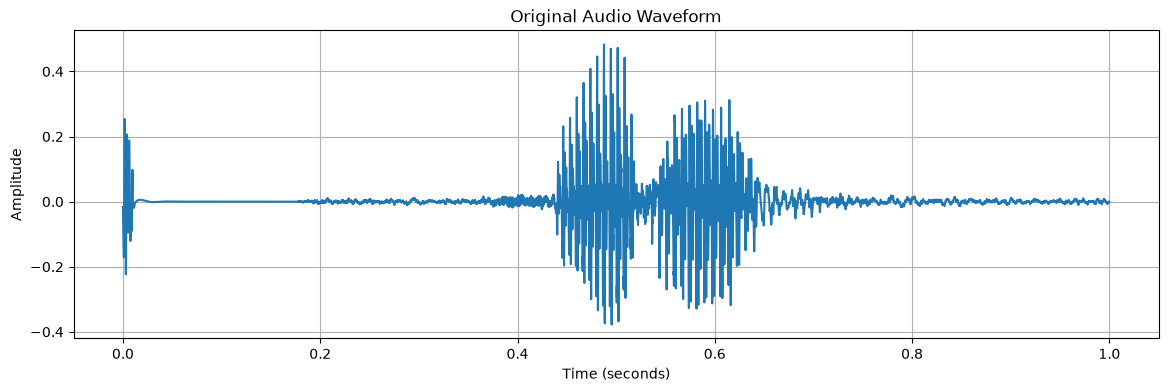

In [15]:
display(Markdown("""
## Step 2: Original waveform

The horizontal axis is time. The vertical axis is the digital
amplitude of the recorded audio.
"""))

plt.figure(figsize=(14, 4))
plt.plot(t_audio, audio)
plt.title("Original Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


## Step 3: Pre-emphasis

Apply y[n] = x[n] - alpha * x[n-1].
The first sample is preserved.


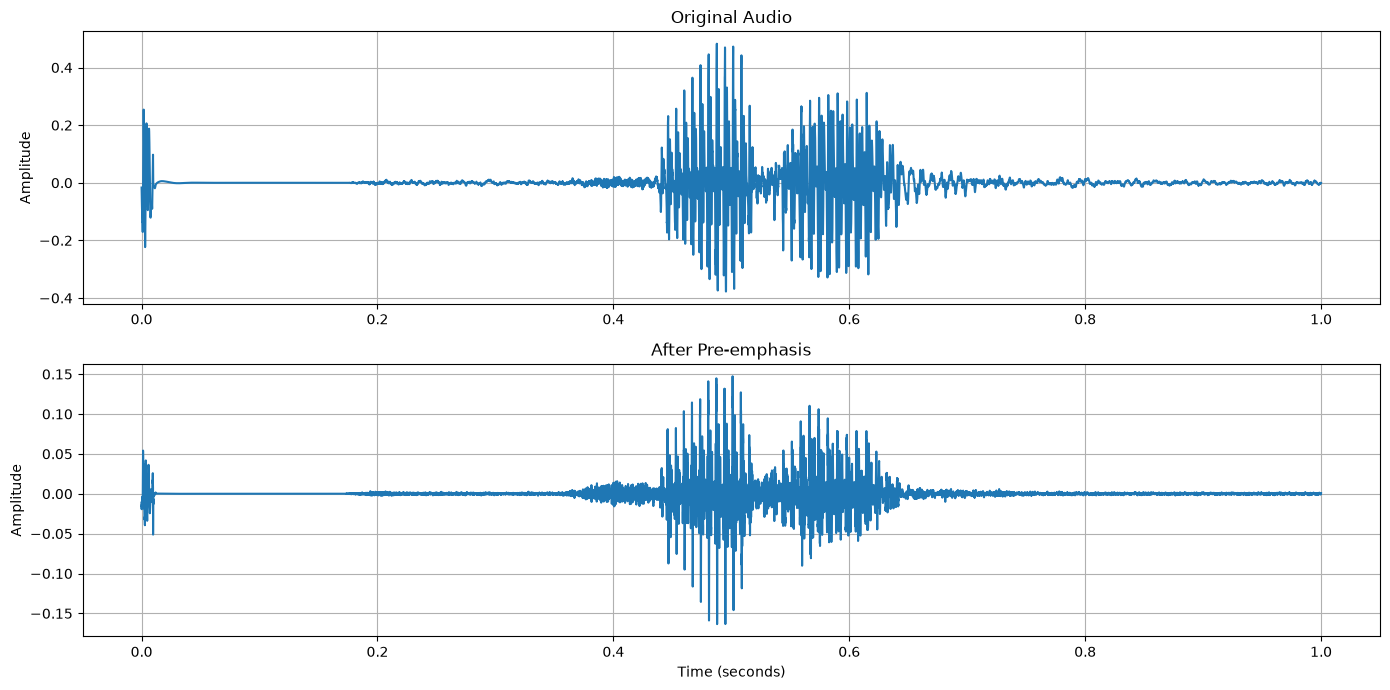

In [16]:
display(Markdown("""
## Step 3: Pre-emphasis

Apply y[n] = x[n] - alpha * x[n-1].
The first sample is preserved.
"""))

alpha = 0.97

pre_emphasized_audio = np.empty_like(audio)
pre_emphasized_audio[0] = audio[0]
pre_emphasized_audio[1:] = (
    audio[1:] - alpha * audio[:-1]
)

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

axes[0].plot(t_audio, audio)
axes[0].set_title("Original Audio")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].plot(t_audio, pre_emphasized_audio)
axes[1].set_title("After Pre-emphasis")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()


## Step 4: Windowing

Multiply each sample by its Hann-window weight.
This reduces the contribution of the frame's edges and helps
reduce spectral leakage during Fourier analysis.


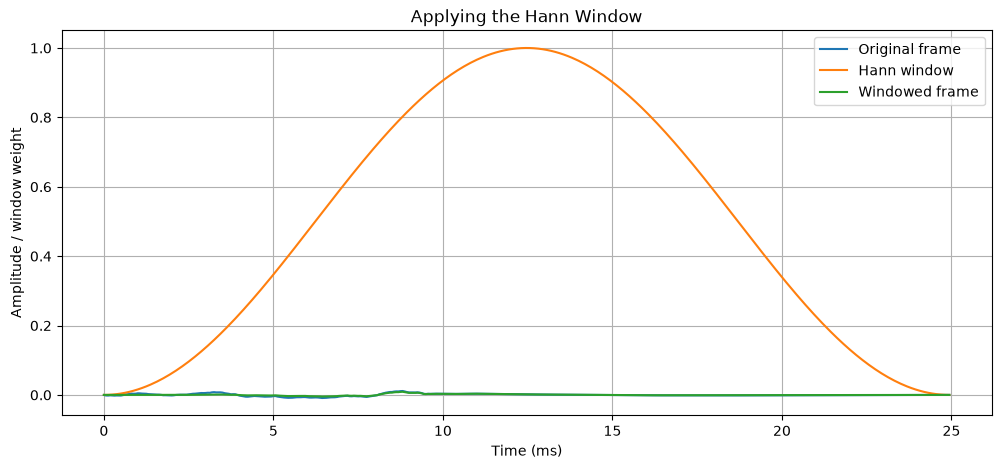

In [6]:
display(Markdown("""
## Step 4: Windowing

Multiply each sample by its Hann-window weight.
This reduces the contribution of the frame's edges and helps
reduce spectral leakage during Fourier analysis.
"""))

hann_window = np.hanning(FRAME)
windowed_frame = frame * hann_window

plt.figure(figsize=(12, 5))
plt.plot(t_frame, frame, label="Original frame")
plt.plot(t_frame, hann_window, label="Hann window")
plt.plot(t_frame, windowed_frame, label="Windowed frame")
plt.title("Applying the Hann Window")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude / window weight")
plt.legend()
plt.grid(True)
plt.show()


## Step 4: Framing

At 16,000 Hz, a 25 ms frame contains 400 samples.
Here we visualize the first frame.


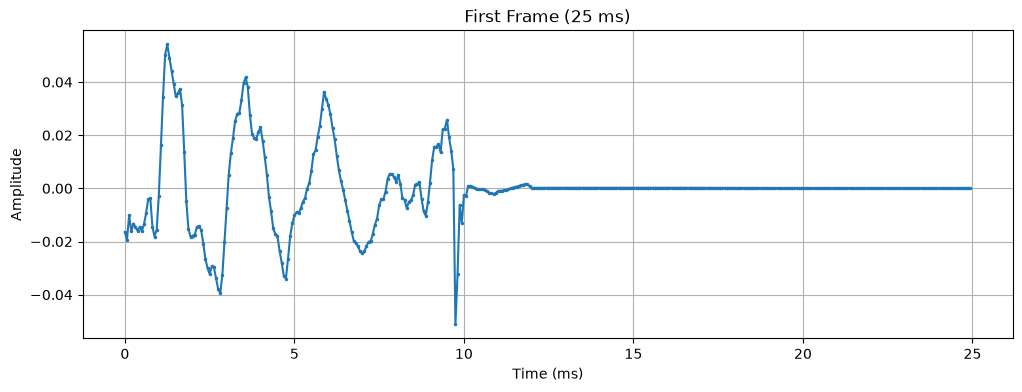

Frame shape: (400,)


In [17]:
display(Markdown("""
## Step 4: Framing

At 16,000 Hz, a 25 ms frame contains 400 samples.
Here we visualize the first frame.
"""))

frame = pre_emphasized_audio[:FRAME]
t_frame = np.arange(FRAME) / SR * 1000

plt.figure(figsize=(12, 4))
plt.plot(t_frame, frame, marker=".", markersize=3)
plt.title("First Frame (25 ms)")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

print("Frame shape:", frame.shape)


## Step 5: Windowing

Multiply the frame by a Hann window to reduce spectral leakage
caused by cutting a continuous signal into short frames.


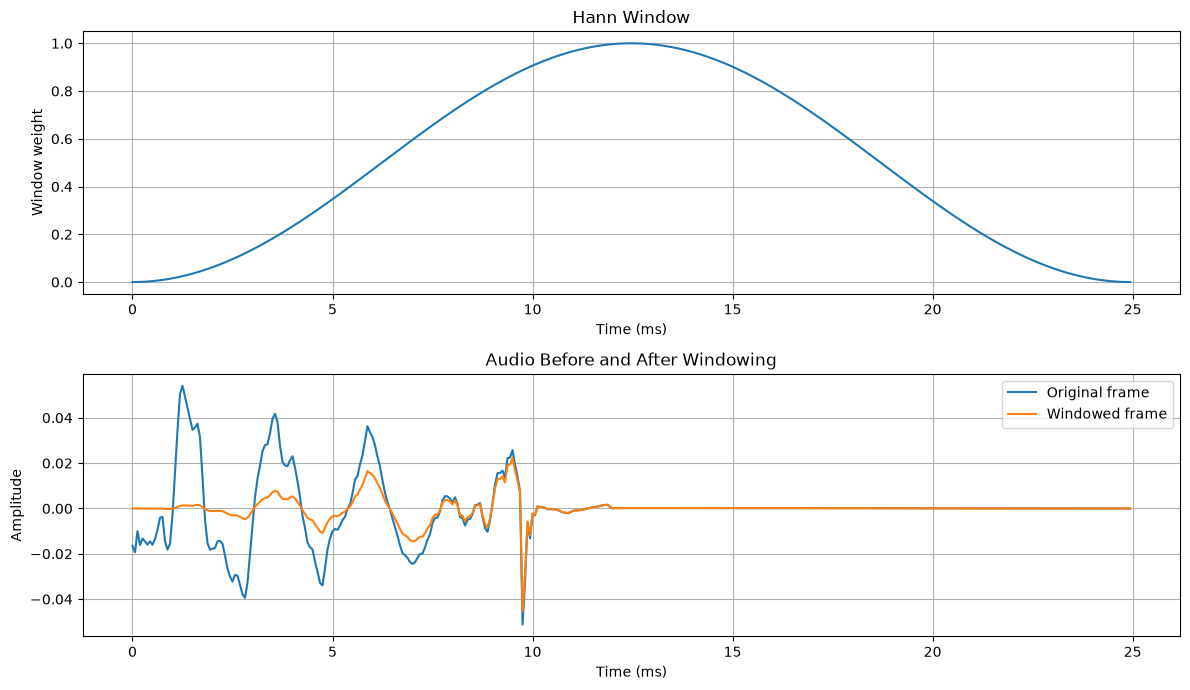

In [18]:
display(Markdown("""
## Step 5: Windowing

Multiply the frame by a Hann window to reduce spectral leakage
caused by cutting a continuous signal into short frames.
"""))

hann_window = np.hanning(FRAME)
windowed_frame = frame * hann_window

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(t_frame, hann_window)
axes[0].set_title("Hann Window")
axes[0].set_xlabel("Time (ms)")
axes[0].set_ylabel("Window weight")
axes[0].grid(True)

axes[1].plot(t_frame, frame, label="Original frame")
axes[1].plot(t_frame, windowed_frame, label="Windowed frame")
axes[1].set_title("Audio Before and After Windowing")
axes[1].set_xlabel("Time (ms)")
axes[1].set_ylabel("Amplitude")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


## Step 6: FFT

The FFT represents the windowed frame in the frequency domain.
Magnitude measures coefficient strength; power is magnitude squared.


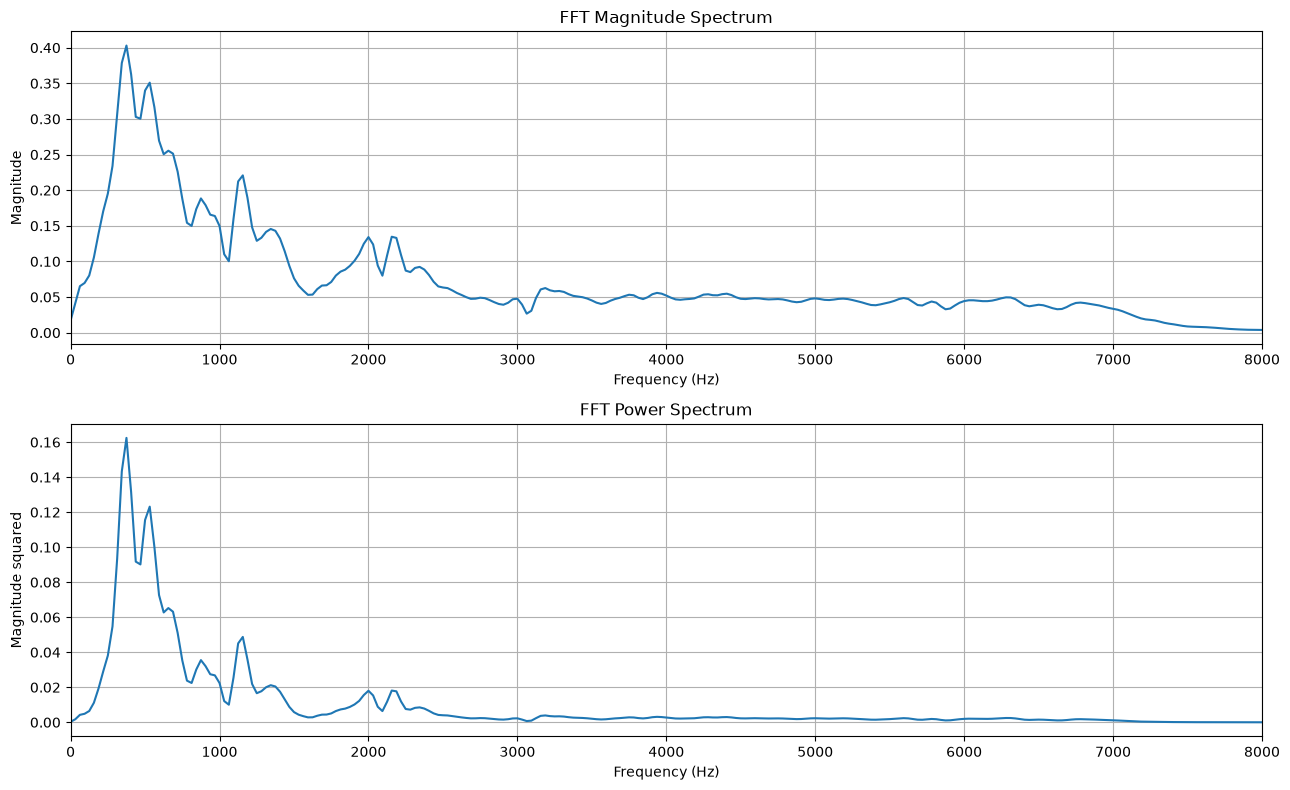

FFT output bins: 257
Bin spacing: 31.25 Hz


In [19]:
display(Markdown("""
## Step 6: FFT

The FFT represents the windowed frame in the frequency domain.
Magnitude measures coefficient strength; power is magnitude squared.
"""))

fft_values = np.fft.rfft(windowed_frame, n=N_FFT)
frequencies = np.fft.rfftfreq(N_FFT, d=1 / SR)

magnitude = np.abs(fft_values)
power = magnitude ** 2

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

axes[0].plot(frequencies, magnitude)
axes[0].set_title("FFT Magnitude Spectrum")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Magnitude")
axes[0].set_xlim(0, SR / 2)
axes[0].grid(True)

axes[1].plot(frequencies, power)
axes[1].set_title("FFT Power Spectrum")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Magnitude squared")
axes[1].set_xlim(0, SR / 2)
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("FFT output bins:", len(frequencies))
print(f"Bin spacing: {SR / N_FFT:.2f} Hz")


## Step 7: Short-Time Fourier Transform (STFT)

Frame length = 25 ms
Hop length = 10 ms
Window = Hann


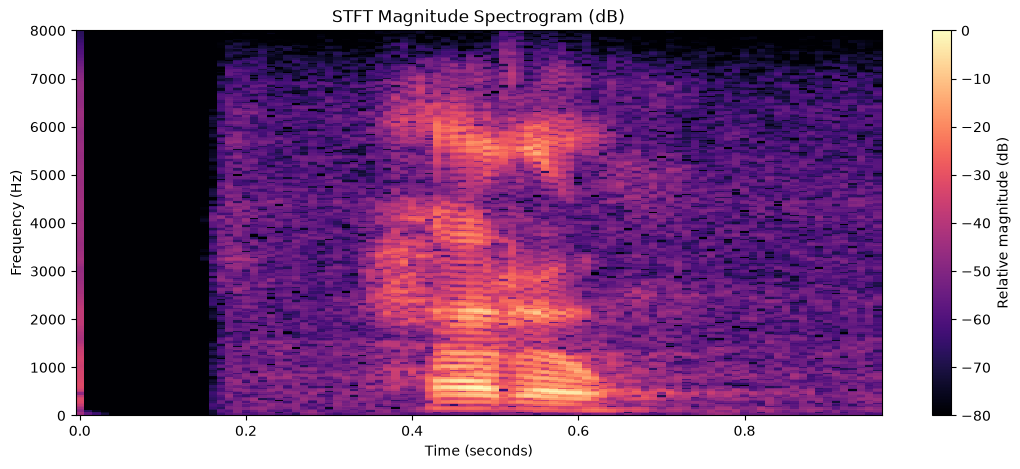

STFT shape (frequency bins, frames): (257, 97)
Number of frequency bins: 257
Number of frames: 97


In [22]:
display(Markdown("""
## Step 7: Short-Time Fourier Transform (STFT)

Frame length = 25 ms
Hop length = 10 ms
Window = Hann
"""))

# Calculate STFT
Z = librosa.stft(
    pre_emphasized_audio,
    n_fft=N_FFT,
    hop_length=HOP,
    win_length=FRAME,
    window="hann",
    center=False
)

# Frequency and time axes
freqs = librosa.fft_frequencies(sr=SR, n_fft=N_FFT)
times = librosa.frames_to_time(
    np.arange(Z.shape[1]),
    sr=SR,
    hop_length=HOP
)

# Magnitude and power
stft_magnitude = np.abs(Z)
stft_power = stft_magnitude ** 2

# Plot STFT
plt.figure(figsize=(13, 5))

plt.pcolormesh(
    times,
    freqs,
    librosa.amplitude_to_db(stft_magnitude, ref=np.max),
    shading="auto",
    cmap="magma",
    vmin=-80,
    vmax=0
)

plt.title("STFT Magnitude Spectrogram (dB)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(0, SR / 2)
plt.colorbar(label="Relative magnitude (dB)")
plt.show()

print("STFT shape (frequency bins, frames):", Z.shape)
print("Number of frequency bins:", len(freqs))
print("Number of frames:", len(times))


## Step 8: Mel filter bank

Each triangular filter combines weighted energy from neighboring
FFT bins into one mel-frequency band.


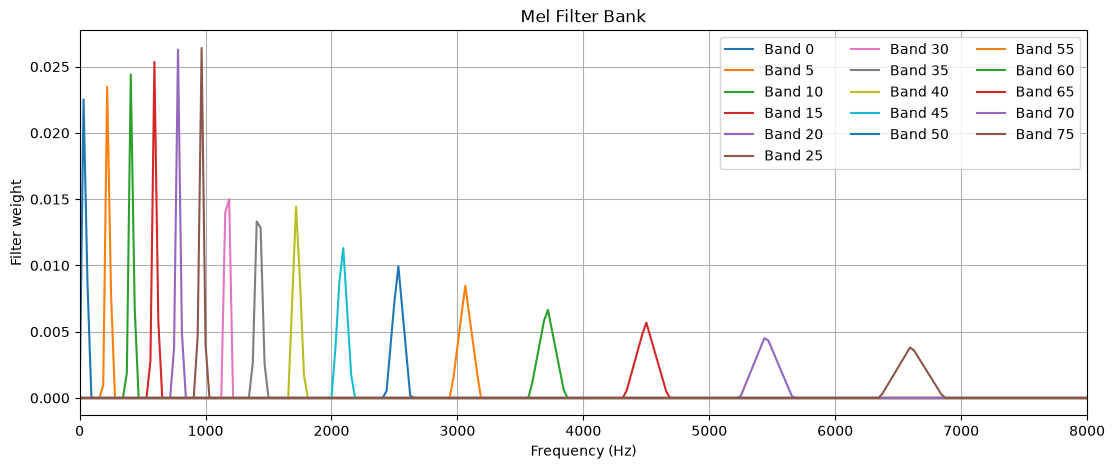

Mel filter bank shape: (80, 257)


In [23]:
display(Markdown("""
## Step 8: Mel filter bank

Each triangular filter combines weighted energy from neighboring
FFT bins into one mel-frequency band.
"""))

mel_filters = librosa.filters.mel(
    sr=SR,
    n_fft=N_FFT,
    n_mels=N_MELS,
    fmin=0,
    fmax=SR / 2,
    norm="slaney"
)

plt.figure(figsize=(13, 5))

for i in range(0, N_MELS, 5):
    plt.plot(frequencies, mel_filters[i], label=f"Band {i}")

plt.title("Mel Filter Bank")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Filter weight")
plt.xlim(0, SR / 2)
plt.legend(ncol=3)
plt.grid(True)
plt.show()

print("Mel filter bank shape:", mel_filters.shape)


## Step 9: Mel spectrogram

Multiply the mel filter bank by the power spectrum at each frame.
This combines the linear FFT bins into 80 mel bands.


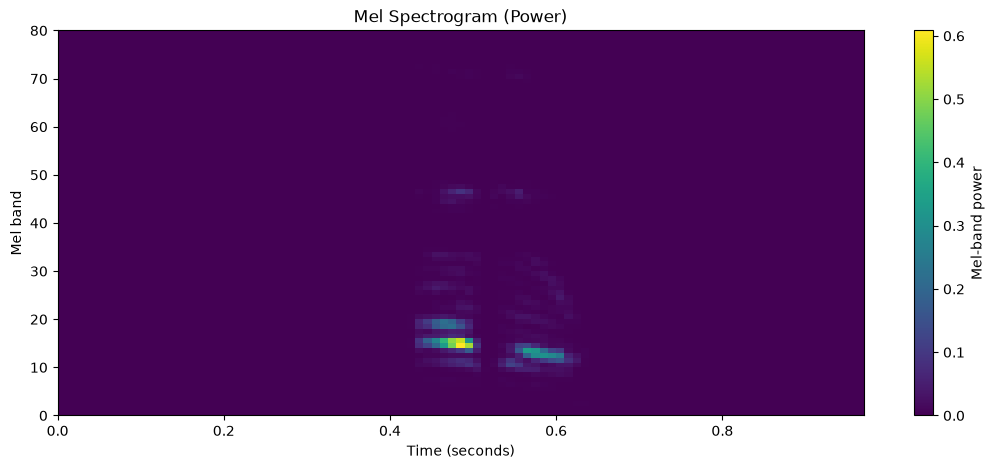

Mel spectrogram shape: (80, 97)


In [24]:
display(Markdown("""
## Step 9: Mel spectrogram

Multiply the mel filter bank by the power spectrum at each frame.
This combines the linear FFT bins into 80 mel bands.
"""))

mel_power = mel_filters @ stft_power

plt.figure(figsize=(13, 5))
plt.imshow(
    mel_power,
    origin="lower",
    aspect="auto",
    extent=[
        times[0],
        times[-1] + HOP / SR,
        0,
        N_MELS
    ]
)
plt.title("Mel Spectrogram (Power)")
plt.xlabel("Time (seconds)")
plt.ylabel("Mel band")
plt.colorbar(label="Mel-band power")
plt.show()

print("Mel spectrogram shape:", mel_power.shape)


## Step 10: Log-mel spectrogram

Convert mel-band power into decibels.
The maximum power is used as the reference, so the strongest
value is 0 dB.


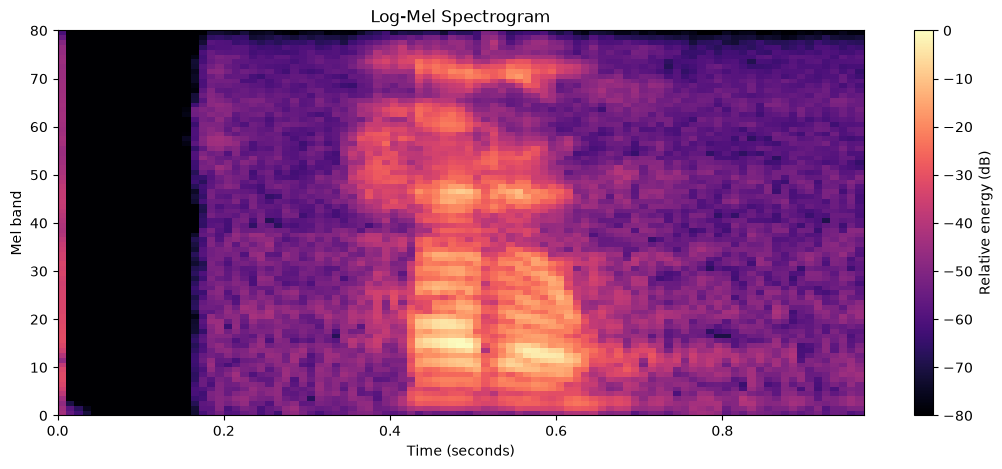

Log-mel feature shape: (80, 97)


In [25]:
display(Markdown("""
## Step 10: Log-mel spectrogram

Convert mel-band power into decibels.
The maximum power is used as the reference, so the strongest
value is 0 dB.
"""))

log_mel = librosa.power_to_db(
    mel_power,
    ref=np.max,
    top_db=80
)

plt.figure(figsize=(13, 5))
plt.imshow(
    log_mel,
    origin="lower",
    aspect="auto",
    extent=[
        times[0],
        times[-1] + HOP / SR,
        0,
        N_MELS
    ],
    cmap="magma",
    vmin=-80,
    vmax=0
)
plt.title("Log-Mel Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Mel band")
plt.colorbar(label="Relative energy (dB)")
plt.show()

print("Log-mel feature shape:", log_mel.shape)


## Step 11: Feature normalization (CMVN)

Subtract each band's mean and divide by its standard deviation.
This changes feature scale; it is not another frequency transform.


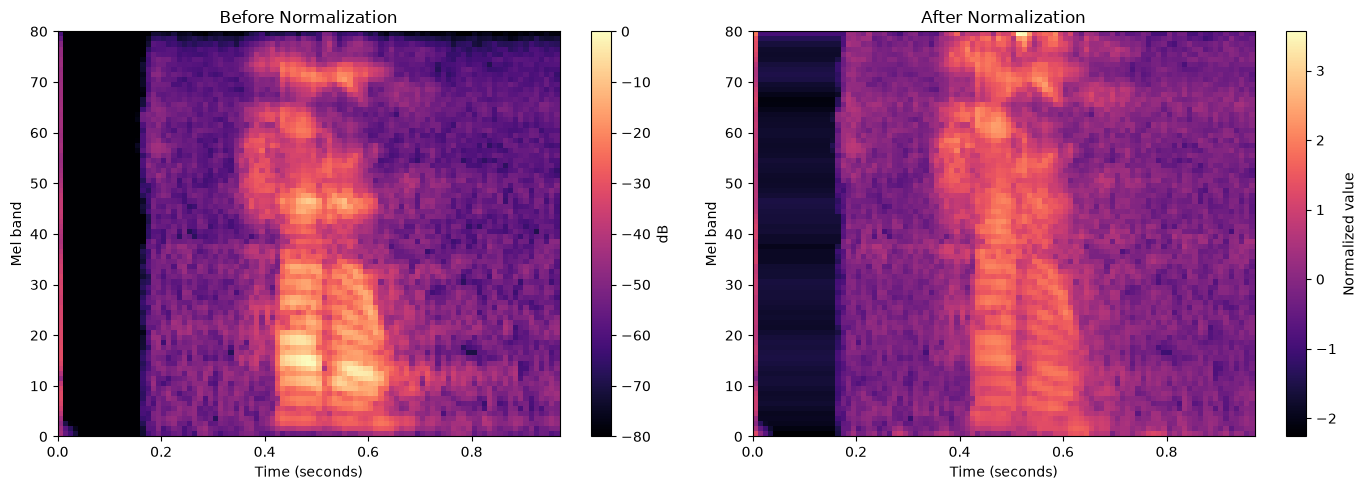

Normalized feature shape: (80, 97)


In [26]:
display(Markdown("""
## Step 11: Feature normalization (CMVN)

Subtract each band's mean and divide by its standard deviation.
This changes feature scale; it is not another frequency transform.
"""))

mean = np.mean(log_mel, axis=1, keepdims=True)
std = np.std(log_mel, axis=1, keepdims=True)

normalized_mel = (log_mel - mean) / (std + 1e-8)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im1 = axes[0].imshow(
    log_mel,
    origin="lower",
    aspect="auto",
    extent=[times[0], times[-1] + HOP / SR, 0, N_MELS],
    cmap="magma",
    vmin=-80,
    vmax=0
)
axes[0].set_title("Before Normalization")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Mel band")
fig.colorbar(im1, ax=axes[0], label="dB")

im2 = axes[1].imshow(
    normalized_mel,
    origin="lower",
    aspect="auto",
    extent=[times[0], times[-1] + HOP / SR, 0, N_MELS],
    cmap="magma"
)
axes[1].set_title("After Normalization")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Mel band")
fig.colorbar(im2, ax=axes[1], label="Normalized value")

plt.tight_layout()
plt.show()

print("Normalized feature shape:", normalized_mel.shape)


## Step 12: Complete pipeline comparison

Compare the original waveform, linear-frequency spectrogram,
mel spectrogram, and final log-mel representation.


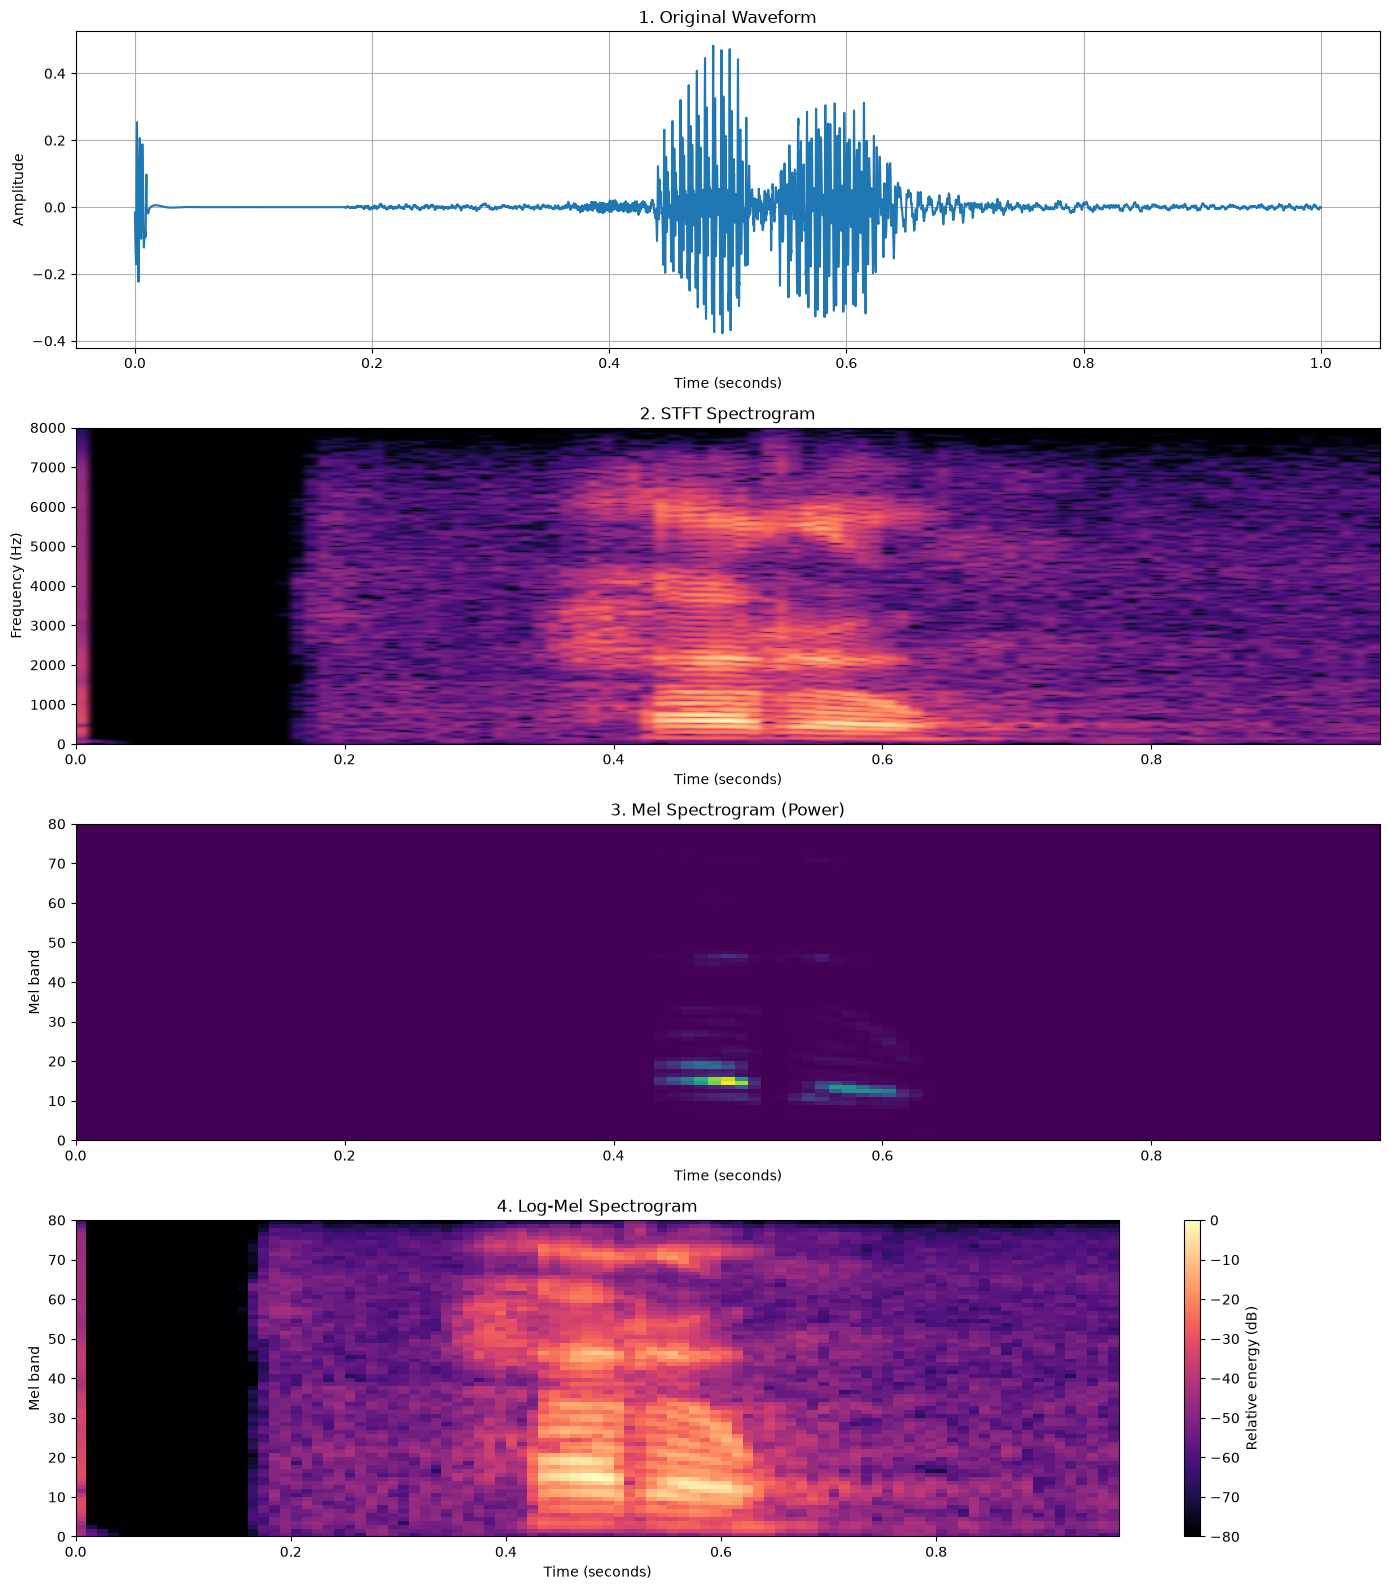

In [27]:
display(Markdown("""
## Step 12: Complete pipeline comparison

Compare the original waveform, linear-frequency spectrogram,
mel spectrogram, and final log-mel representation.
"""))

fig, axes = plt.subplots(4, 1, figsize=(14, 16))

axes[0].plot(t_audio, audio)
axes[0].set_title("1. Original Waveform")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].imshow(
    librosa.amplitude_to_db(stft_magnitude, ref=np.max),
    origin="lower",
    aspect="auto",
    extent=[times[0], times[-1] + HOP / SR, 0, SR / 2],
    cmap="magma",
    vmin=-80,
    vmax=0
)
axes[1].set_title("2. STFT Spectrogram")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Frequency (Hz)")
axes[1].set_ylim(0, SR / 2)

axes[2].imshow(
    mel_power,
    origin="lower",
    aspect="auto",
    extent=[times[0], times[-1] + HOP / SR, 0, N_MELS]
)
axes[2].set_title("3. Mel Spectrogram (Power)")
axes[2].set_xlabel("Time (seconds)")
axes[2].set_ylabel("Mel band")

im = axes[3].imshow(
    log_mel,
    origin="lower",
    aspect="auto",
    extent=[times[0], times[-1] + HOP / SR, 0, N_MELS],
    cmap="magma",
    vmin=-80,
    vmax=0
)
axes[3].set_title("4. Log-Mel Spectrogram")
axes[3].set_xlabel("Time (seconds)")
axes[3].set_ylabel("Mel band")
fig.colorbar(im, ax=axes[3], label="Relative energy (dB)")

plt.tight_layout()
plt.show()